# Models

Linear regression and XGBoost forecasts of BIST 100 volatility over the next 21 trading days, scored next to the baselines on the same test period (2018 onward).

Both models get the same inputs, all known at BIST's close on the forecast date:

- **rv_1d, rv_5d, rv_21d**: realized volatility over the last day, week and month. The short windows react fast, and the long one pulls the forecast toward normal levels. This mix is the classic HAR model of volatility.
- **vix**: the last VIX close before today, for global stress.

Each model is fitted once on the training years, from 1997 or from 2003, without the last 21 training rows: their targets reach into the test period.

In [16]:
# Pick up edits to src/volforecast without restarting the kernel
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [17]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

from volforecast import baselines
from volforecast.data import load
from volforecast.evaluate import HORIZON, TEST_START, Split, dm_table, score_table
from volforecast.features import build_dataset, log_returns
from volforecast.models import fit_predict, make_xgboost

In [18]:
FEATURES = ["rv_1d", "rv_5d", "rv_21d", "vix"]
TRAIN_STARTS = {"from 1997": "1997-01-01", "from 2003": "2003-01-01"}

xu100 = load("xu100")
vix = load("vix")
r = log_returns(xu100["Close"]).dropna()
data = build_dataset(r, vix["Close"], HORIZON)

## Fitting

The baselines and the two models come from `src/volforecast` (`baselines.py` and `models.py`), so the scores below show everything side by side. XGBoost uses small trees (depth 3) and a slow learning rate, because there are only about 3,700 training days from 2003 on.

In [19]:
forecasts = {}
linear_models: dict[str, LinearRegression] = {}
xgb_models: dict[str, XGBRegressor] = {}
for scenario, train_start in TRAIN_STARTS.items():
    split = Split(train_start, TEST_START, HORIZON)
    linear = LinearRegression()
    xgb = make_xgboost(n_estimators=300, max_depth=3, learning_rate=0.05)
    models = {
        "historical average": baselines.historical_average(data, split),
        "naive": data["rv_21d"],
        "VIX": baselines.rescaled_vix(data, split),
        "GARCH": baselines.garch(r, split),
        "linear regression": fit_predict(linear, data, FEATURES, split),
        "XGBoost": fit_predict(xgb, data, FEATURES, split),
    }
    forecasts[scenario] = pd.DataFrame(models).loc[TEST_START:]
    linear_models[scenario] = linear
    xgb_models[scenario] = xgb

## Scores

The same scores as in the baselines notebook, on the same test dates: bias, MAE and RMSE in volatility points, and QLIKE on variances. Lower is better, and bias should be close to 0.

In [20]:
tables = {scenario: score_table(frame, data["target"]) for scenario, frame in forecasts.items()}
pd.concat(tables).round(3)

bias     MAE    RMSE  QLIKE
from 1997 historical average  7.839  10.891  12.299  0.336
          naive              -0.129   8.191  11.176  0.402
          VIX                 7.003  10.573  13.080  0.320
          GARCH               2.706   7.887  10.302  0.257
          linear regression   2.696   7.747   9.985  0.243
          XGBoost             1.589   7.447   9.924  0.258
from 2003 historical average  0.504   7.270   9.490  0.266
          naive              -0.129   8.191  11.176  0.402
          VIX                 0.940   7.636   9.781  0.264
          GARCH               1.162   7.167   9.521  0.247
          linear regression   0.321   6.846   9.099  0.237
          XGBoost             0.186   7.182   9.597  0.271

## Is the edge real?

Diebold–Mariano tests of each forecast against the linear regression, all trained from 2003. For each loss (absolute error behind MAE, squared error behind RMSE, and QLIKE), a positive statistic means the other forecast has the higher loss. The p-value is the chance of a gap at least this large if both forecasts were equally good; below 0.05 is the usual bar. Overlapping 21-day targets make neighboring errors correlated, and the test accounts for that.

In [21]:
tests = dm_table(forecasts["from 2003"], data["target"], "linear regression", HORIZON)
tests.round(3)

,MAE stat,MAE p,MSE stat,MSE p,QLIKE stat,QLIKE p
historical average,1.453,0.146,1.086,0.277,1.404,0.160
naive,3.734,0.000,4.293,0.000,4.466,0.000
VIX,2.974,0.003,2.117,0.034,1.427,0.154
GARCH,2.124,0.034,2.059,0.040,1.282,0.200
XGBoost,2.553,0.011,3.106,0.002,3.259,0.001


## What the models learned

Trained from 2003: the linear regression's coefficients (forecast points per point of each input) and XGBoost's feature importance (each input's share of the total).

In [22]:
linear = linear_models["from 2003"]
xgb = xgb_models["from 2003"]
learned = {
    "linear coefficient": pd.Series(linear.coef_, index=FEATURES),
    "XGBoost importance": pd.Series(xgb.feature_importances_, index=FEATURES),
}
print(f"linear intercept: {linear.intercept_:.2f}")
pd.DataFrame(learned).round(3)

linear intercept: 10.32


,linear coefficient,XGBoost importance
rv_1d,0.016,0.073
rv_5d,0.124,0.209
rv_21d,0.301,0.491
vix,0.219,0.228


Forecasts against what actually happened, training from 2003.

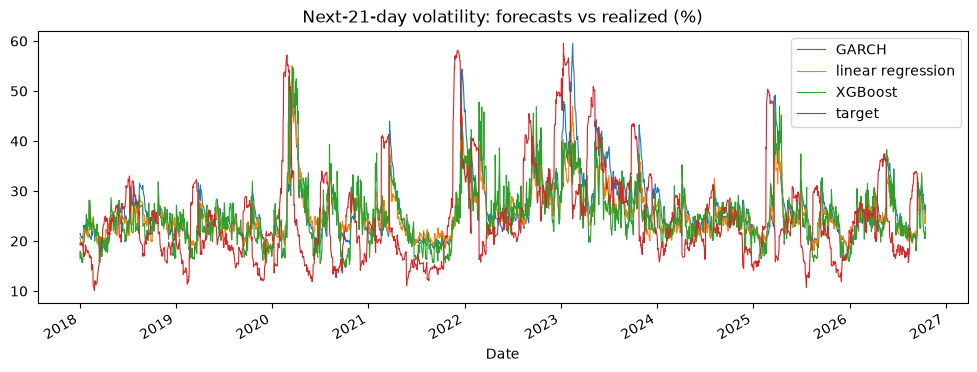

In [23]:
test = forecasts["from 2003"][["GARCH", "linear regression", "XGBoost"]].join(data["target"])
test.plot(figsize=(12, 4), lw=0.8, title="Next-21-day volatility: forecasts vs realized (%)")
plt.show()

## Findings

- **Linear regression trained from 2003 is the best model.** It has the lowest MAE (6.85), RMSE (9.10) and QLIKE (0.237) of all twelve forecasts, with almost no bias (0.3). Against GARCH, the best baseline, that's about 4–5% lower on each score.
- **XGBoost doesn't beat it.** Trained from 2003, it lands at GARCH's level (MAE 7.18, RMSE 9.60) with a worse QLIKE (0.271). With four inputs and about 3,700 heavily overlapping training days, trees probably have little to find beyond what a straight line already captures.
- **What the linear model learned:** forecast ≈ 10.3 + 0.30·rv_21d + 0.12·rv_5d + 0.02·rv_1d + 0.22·VIX. The volatility coefficients add up to 0.44, so the forecast moves less than half as much as recent volatility and leans on the long-run level. Yesterday's volatility barely matters, and VIX adds information that BIST's own past doesn't have. XGBoost ranks the inputs the same way (rv_21d 0.49, VIX 0.23, rv_5d 0.21, rv_1d 0.07).
- **2003 beats 1997 again** for the linear regression, on every score. For XGBoost, 2003 gives better MAE and RMSE but a worse QLIKE, probably because the crisis years give it more examples of high volatility to learn spikes from.
- **The edge is real against most, but not all.** Diebold–Mariano tests say the linear regression is significantly better (p < 0.05) than naive and XGBoost on every loss, and than GARCH and VIX on MAE and RMSE, but not on QLIKE. Against the historical average, no gap is significant (p = 0.15–0.28): over 2018–2026, the linear regression can't be told apart from forecasting the long-run level.